---
title: "Wiry cykloniczne w modelu płytkiej wody"
author: "Karol Ożóg (419388)"
lang: pl

format:
  pdf:
    documentclass: article
    fontsize: 10pt
    geometry:
      - top=10mm
      - bottom=15mm
      - left=10mm
      - right=10mm
    fig-pos: "H"

header-includes:
  - |
    \usepackage{titling}
    \setlength{\droptitle}{-4em}
    \pretitle{\begin{center}\large\bfseries}
    \posttitle{\end{center}\vspace{0.5em}}
    \preauthor{\begin{center}\normalsize}
    \postauthor{\end{center}\vspace{-2em}}

execute:
  echo: false
  warning: false
  error: false
---

In [23]:
import os
os.environ["NUMBA_THREADING_LAYER"]='workqueue'
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions

In [24]:
class CyclogenesisSolver:
    def __init__(self, *, h_initial, options=None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        grid = h_initial.shape
        stepper = Stepper(options=options, grid=grid)
        kwargs = {
            'boundary_conditions': [boundary_conditions.Periodic()] * 2, 
            'halo': options.n_halo
            }
        advectees = {
            "h":  ScalarField(h_initial.astype(float), **kwargs),
            "uh": ScalarField(np.zeros(grid), **kwargs),
            "vh": ScalarField(np.zeros(grid), **kwargs),
        }
        self.advector = VectorField((np.zeros((grid[0]+1, grid[1])),
                                     np.zeros((grid[0], grid[1]+1))
                                     ),**kwargs)
        self.solvers = {k: Solver(stepper, v, self.advector) for k, v in advectees.items()}

    def __getitem__(self, key):
        return self.solvers[key].advectee.get()

    def _update_courant_numbers(self, dt_over_dxy, eps):
        h = np.maximum(self['h'], eps)
        for axis, key in enumerate(("uh", "vh")):
            vel = self[key] / h
            face = 0.5 * (vel + np.roll(vel, 1, axis=axis))
            comp = self.advector.get_component(axis)
            n = vel.shape[axis]
            if axis == 0:
                comp[:n, :] = face * dt_over_dxy[0]; comp[n, :] = comp[0, :]
            else:
                comp[:, :n] = face * dt_over_dxy[1]; comp[:, n] = comp[:, 0]
            assert np.amax(np.abs(comp)) <= 1, "liczba Couranta > 1 - zmniejsz dt"

    def _apply_half_sources(self, *, g, f_coriolis, r_friction, dt, dxy):
        h, uh, vh = self['h'], self['uh'], self['vh']
        dzdx = (np.roll(h, -1, 0) - np.roll(h, 1, 0)) / (2 * dxy[0])
        dzdy = (np.roll(h, -1, 1) - np.roll(h, 1, 1)) / (2 * dxy[1])
        uh -= 0.5 * dt * g * h * dzdx
        vh -= 0.5 * dt * g * h * dzdy
        th = f_coriolis * 0.5 * dt
        c, s = np.cos(th), np.sin(th)
        u_new, v_new = c * uh + s * vh, -s * uh + c * vh
        friction = np.exp(-r_friction * 0.5 * dt)
        uh[:] = u_new * friction
        vh[:] = v_new * friction

    def _apply_mass_source(self, Q, dt):
        h = self['h']
        h_new = np.maximum(h + Q * dt, 1e-6)
        ratio = np.where(Q < 0, h_new / h, 1.0)
        self['uh'][:] *= ratio
        self['vh'][:] *= ratio
        h[:] = h_new

    def __call__(self, *, nt, g, f, r, dt, dxy=(1., 1.), Q=None, outfreq=10, eps=1e-7):
        dt_over_dxy = (dt / dxy[0], dt / dxy[1])
        out = {k: [] for k in self.solvers}
        out['t'] = []
        for it in range(nt + 1):
            if it != 0:
                self._update_courant_numbers(dt_over_dxy, eps)
                self.solvers["h"].advance(n_steps=1)
                if Q is not None:
                    self._apply_mass_source(Q, dt)
                self._apply_half_sources(g=g, f_coriolis=f, r_friction=r, dt=dt, dxy=dxy)
                self.solvers["uh"].advance(n_steps=1)
                self.solvers["vh"].advance(n_steps=1)
                self._apply_half_sources(g=g, f_coriolis=f, r_friction=r, dt=dt, dxy=dxy)
            if it % outfreq == 0:
                for k in self.solvers: out[k].append(self[k].copy())
                out['t'].append(it * dt)
        return out

In [ ]:
def make_Q(N, q0=0.002, sigma=6., L=64.):
    x = (np.arange(N)+.5)*L/N
    X, Y = np.meshgrid(x, x, indexing='ij')
    Q = -q0*np.exp(-np.hypot(X-L/2, Y-L/2)**2/(2*sigma**2))
    return Q - Q.mean()


def run(N, dt, T, q0, L=64., H=1., g=1., f=0.05, r=0.06, sigma=6.):
    dx = L/N
    Q = make_Q(N, q0=q0, sigma=sigma, L=L)
    nt = int(round(T/dt))
    out = CyclogenesisSolver(h_initial=np.full((N, N), H))(
        nt=nt, g=g, f=f, r=r, dt=dt, dxy=(dx, dx), Q=Q, outfreq=nt/10)
    return Q, dx, out['h'][-1]-H, out['uh'][-1]/out['h'][-1], out['vh'][-1]/out['h'][-1]

def linear_exact(Q, dx, T, H=1., g=1., f=0.05, r=0.06):
    N = Q.shape[0]
    k = 2*np.pi*np.fft.fftfreq(N, d=dx)
    KX, KY = np.meshgrid(k, k, indexing='ij')
    A = np.zeros((N, N, 3, 3), complex)
    A[..., 0, 1] = -1j*H*KX; A[..., 0, 2] = -1j*H*KY
    A[..., 1, 0] = -1j*g*KX; A[..., 1, 1] = -r; A[..., 1, 2] = f
    A[..., 2, 0] = -1j*g*KY; A[..., 2, 1] = -f; A[..., 2, 2] = -r
    w, V = np.linalg.eig(A)
    b = np.zeros((N, N, 3), complex); b[..., 0] = np.fft.fft2(Q)
    c = np.linalg.solve(V, b[..., None])[..., 0]
    with np.errstate(all='ignore'):
        phi = np.where(np.abs(w) > 1e-12, (np.exp(w*T)-1)/w, T)
    Yh = np.einsum('xyij,xyj->xyi', V, phi*c)
    Yh[0, 0, :] = 0
    return [np.fft.ifft2(Yh[..., i]).real for i in range(3)]

def l2(a, b):
    return np.linalg.norm(a - b)


def cut_domain_half(domain):
    N = domain.shape[0]
    return domain[:, N//2-1:N//2+1].mean(axis=1)


# Cel analizy

Celem analizy jest zbadanie powstawania wiru cyklonicznego wywołanego lokalnym ujściem masy w dwuwymiarowym modelu płytkiej wody. Początkowa głębokość jest stała, $h(x,y,0)=H$. W środku periodycznej domeny znajduje się ujście masy o rozkładzie gaussowskim z odjętą średnią, więc całkowita masa wody pozostaje stała. W analizie uwzględniłem gradient ciśnienia, siłę Coriolisa i tarcie Rayleigha.


In [ ]:
N = 64
L = 64.0
H = 1.0
g = 1.0

f = 0.05
r = 0.06
dt = 0.1

sigma = 6.0
q0 = 0.002

NT = 1000
OUTFREQ = 100

Q = make_Q(N, q0=q0, sigma=sigma, L=L)

output = CyclogenesisSolver(h_initial=np.full((N, N), H))(
    nt=NT, g=g, f=f, r=r, dt=dt, dxy=(L / N, L / N), Q=Q, outfreq=OUTFREQ
)


# Model fizyczny i metoda numeryczna

Równania płytkiej wody 2D dla zmiennych zachowawczych $h$, $uh$, $vh$ (płaskie dno) opisano wzorami: 
$$
\begin{aligned}
\partial_t h + \nabla\cdot(\vec{u}h) &= Q, \\
\partial_t(hu) + \nabla\cdot(\vec{u}hu) &= -gh\,\partial_x h + fhv - rhu, \\
\partial_t(hv) + \nabla\cdot(\vec{u}hv) &= -gh\,\partial_y h + fhu - rhv.
\end{aligned}
$$,
 gdzie $u=uh/h$, $v=vh/h$, $Q$ to ujście masy, $f$ parametr Coriolisa, $r$ współczynnik tarcia Rayleigha. Ujemna $\eta=h-H$ oznacza lokalne obniżenie poziomu wody. Tam, gdzie $Q<0$, pęd jest skalowany proporcjonalnie do zmiany $h$, aby prędkość nie zmieniała się sztucznie. Domyślnie użyte parametry to: $L=64,\ H=1,\ g=1,\ f=0.05,\ r=0.06,\ q_0=0.002,\ \sigma=6$ ($q_0$ to siła, $\sigma$ szerokość ujścia), siatka $N=64$ ($\Delta x=1$), $\Delta t=0.1$, $T=100$.

Transport wykonuje PyMPDATA, osobny solver dla każdej zmiennej, ze wspólnym polem adwekcji. W solverze użyłem opcji `nonoscillatory=True`, `infinite_gauge=True`, pozostałe domyślne (m.in. `n_iters=2`). Warunki brzegowe: periodyczne w obu kierunkach (`Periodic()`), halo zgodne z `options.n_halo`. Siatka  jest kwadratowa, prędkości adwekcji na ścianach komórek (uśrednione $u=uh/h$), z dolnym ograniczeniem `eps=1e-7` dla $h$, po dodaniu źródła $h\ge10^{-6}$ i kontrolą liczby Couranta $\le 1$. Kolejność w kroku: transport $h$, ujście masy, połówkowy krok źródeł, transport $uh$ i $vh$, połówkowy krok źródeł. Połówkowy krok źródeł ($\Delta t/2$) obejmuje gradient ciśnienia (różnice centralne), obrót pędu o kąt $\theta=f\Delta t/2$ (Coriolis) i tłumienie czynnikiem $D=\exp(-r\Delta t/2)$ (tarcie). Pola zapisywane są co `OUTFREQ=100` kroków.


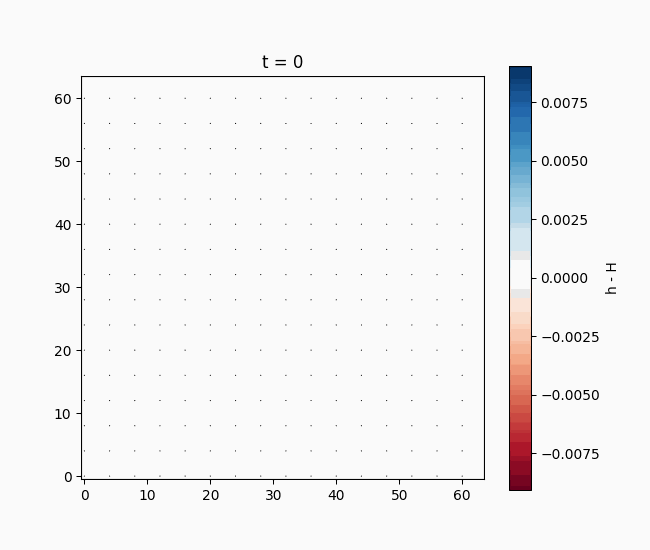

HTML(value="<a href='.\\tmp8rk03891.gif' target='_blank'>.\\tmp8rk03891.gif</a><br>")

In [ ]:
#| output: false
hmin = min((h - H).min() for h in output['h'])
umax = max(np.hypot(u/h, v/h).max() for u, v, h in zip(output['uh'], output['vh'], output['h']))
S = 4
xi, yi = np.indices((N, N))
def plot(i):
    h = output['h'][i]; u = output['uh'][i]/h; v = output['vh'][i]/h
    fig, ax = pyplot.subplots(figsize=(6.5, 5.5))
    im = ax.imshow((h - H).T, origin='lower', cmap='RdBu', vmin=hmin, vmax=-hmin)
    ax.quiver(xi[::S, ::S], yi[::S, ::S], u[::S, ::S], v[::S, ::S],
              scale=umax*25, color='k', width=.003)
    ax.set_title(f"t = {output['t'][i]:.0f}")
    pyplot.colorbar(im, ax=ax, label='h - H')
    return fig

show_anim(plot, range(len(output["h"])),gif_file="cyklogeneza.gif")

# Wynik podstawowej symulacji

Lokalne ujście masy powoduje obniżenie poziomu wody w pobliżu środka
domeny. Gradient ciśnienia generuje przepływ w kierunku obszaru obniżonego
poziomu, natomiast siła Coriolisa odchyla ten przepływ i prowadzi do
powstania wiru.

Ewolucję rozwiązania przedstawiono na animacji `cyklogeneza.gif`, dołączonej do artefaktów sprawozdania. Widoczne są na niej zmiany wysokości $\eta=h-H$ oraz pola prędkości w kolejnych chwilach czasu. Tarcie Rayleigha ogranicza amplitudę prędkości i powoduje stopniowe rozpraszanie energii zaburzenia.


In [ ]:
Ns = [32, 64, 128, 256]
res = {}
T = 100.0

for N in Ns:
    dx = L / N
    dt_space = 0.1

    Q, dx, eta, u, v = run(N=N, dt=dt_space, T=T, q0=q0, L=L, H=H, g=g, f=f, r=r, sigma=sigma)

    eta_ex, u_ex, v_ex = linear_exact(Q, dx, T, H=H, g=g, f=f, r=r)

    res[N] = {
        "dx": dx,
        "eta": eta,
        "eta_ex": eta_ex,
        "u": u,
        "u_ex": u_ex,
        "v": v,
        "v_ex": v_ex,
        "err_eta": l2(eta, eta_ex) / l2(eta_ex, np.zeros_like(eta_ex)),
        "err_u": l2(u, u_ex) / l2(u_ex, np.zeros_like(u_ex)),
        "err_v": l2(v, v_ex) / l2(v_ex, np.zeros_like(v_ex))
    }


dxs = np.array([res[N]["dx"] for N in Ns])
errs_eta = np.array([res[N]["err_eta"] for N in Ns])
errs_u = np.array([res[N]["err_u"] for N in Ns])
errs_v = np.array([res[N]["err_v"] for N in Ns])

Nref = 512
Qref = make_Q(Nref, q0=q0, sigma=sigma, L=L)
dx_ref = L / Nref

eta_ref, u_ref, v_ref = linear_exact(Qref, dx_ref, T, H=H, g=g, f=f, r=r)

x_ref = (np.arange(Nref) + 0.5) * dx_ref

N=  32  dx=2.0000  błąd eta=3.0491e-02  błąd u=2.0742e-02  błąd v=2.0742e-02
N=  64  dx=1.0000  błąd eta=1.3353e-02  błąd u=1.0759e-02  błąd v=1.0759e-02
N= 128  dx=0.5000  błąd eta=8.6365e-03  błąd u=8.2713e-03  błąd v=8.2713e-03
N= 256  dx=0.2500  błąd eta=7.1919e-03  błąd u=7.6003e-03  błąd v=7.6003e-03


# Rozwiązanie analityczne i ocena błędu

Do oceny dokładności użyto rozwiązania układu zlinearyzowanego. Zakładamy $h=H+\eta$, $|\eta|\ll H$ i pomijamy składniki nieliniowe:
$$
\begin{aligned}
\partial_t\eta&=-H\nabla\cdot\vec u+Q \\
\partial_t u&=-g\partial_x\eta+fv-ru \\
\partial_t v&=-g\partial_y\eta-fu-rv
\end{aligned}
$$,
Po transformacie Fouriera każdy mod spełnia układ $3\times3$, rozwiązywany przez diagonalizację macierzy i całkowanie stałego wymuszenia, po czym wykonywana jest odwrotna transformata. Jest to rozwiązanie dokładne dla modelu liniowego, ale nie dla pełnych równań nieliniowych, więc porównanie zawiera błąd dyskretyzacji i wpływ nieliniowości. Błąd względny w normie $L_2$: $E_\phi=\frac{\|\phi_{\mathrm{num}}-\phi_{\mathrm{an}}\|_2}{\|\phi_{\mathrm{an}}\|_2}$.

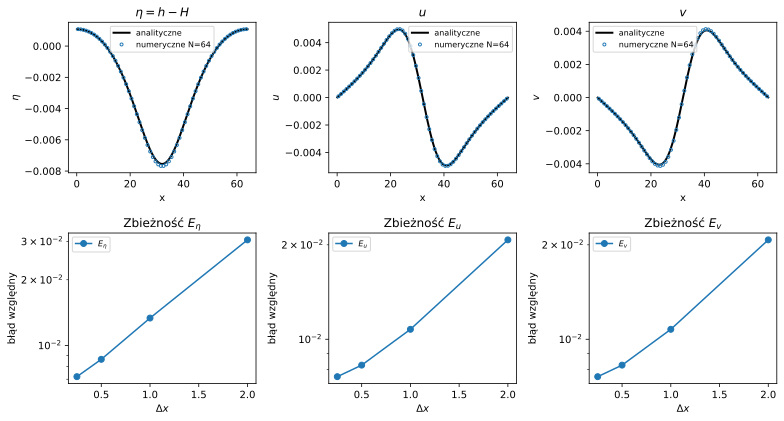

In [31]:
N_plot = 64
x_plot = (np.arange(N_plot) + 0.5) * res[N_plot]["dx"]

fig, ax = pyplot.subplots(2, 3, figsize=(11, 6))

fields = [
    ("eta", r"$\eta=h-H$", eta_ref, r"$\eta$"),
    ("u", r"$u$", u_ref, r"$u$"),
    ("v", r"$v$", v_ref, r"$v$")
]

for j, (key, label, reference, ylabel) in enumerate(fields):
    ax[0, j].plot(x_ref, cut_domain_half(reference),"k-", lw=2, label="analityczne")
    ax[0, j].plot(x_plot, cut_domain_half(res[N_plot][key]), "o", ms=3, mfc="none", label=f"numeryczne N={N_plot}")
    ax[0, j].set(xlabel="x", ylabel=ylabel, title=label)
    ax[0, j].legend(fontsize=8)

errors = [errs_eta, errs_u, errs_v]
error_labels = [
    r"$E_\eta$",
    r"$E_u$",
    r"$E_v$"
]

for j, (error, label) in enumerate(zip(errors, error_labels)):
    ax[1, j].semilogy(dxs, error, "o-", label=label)
    ax[1, j].set(xlabel=r"$\Delta x$", ylabel="błąd względny", title=f"Zbieżność {label}")
    ax[1, j].legend(fontsize=8)

fig.tight_layout()
show_plot(fig=fig)

Na pierwszym wierszu przedstawiono przekroje przez rozwiązanie numeryczne
i analityczne przez środek upływu dla $\eta$ oraz obu składowych prędkości, dla siatki 64x64 (z dx=1) i kroku czasowego dt=0.1 Dobra zgodność krzywych oznacza, że rozwiązanie numeryczne poprawnie odtwarza zarówno strukturę zaburzenia wysokości, jak i cyrkulację. W drugim wierszu przedstawiono względne błędy $L_2$ w funkcji kroku przestrzennego dla stałego kroku czasowego dt=0.1. Błąd wszystkich analizowanych zmiennych maleje wraz ze zmniejszaniem $\Delta x$, co potwierdza zbieżność przestrzenną metody.

In [30]:
N_time = 64
dts = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])

time_solutions = {
    "eta": [],
    "u": [],
    "v": []
}

for dt_time in dts:
    Q_time, dx_time, eta, u, v = run(N=N_time, dt=dt_time, T=T, q0=q0, L=L, H=H, g=g, f=f, r=r, sigma=sigma)

    time_solutions["eta"].append(eta)
    time_solutions["u"].append(u)
    time_solutions["v"].append(v)

eta_ex_time, u_ex_time, v_ex_time = linear_exact(Q_time, dx_time, T, H=H, g=g, f=f, r=r)

exact_time = {
    "eta": eta_ex_time,
    "u": u_ex_time,
    "v": v_ex_time
}

err_time = {}

for key in ("eta", "u", "v"):
    norm = l2(exact_time[key], np.zeros_like(exact_time[key]))
    err_time[key] = np.array([
        l2(solution, exact_time[key]) / norm
        for solution in time_solutions[key]
    ])

Zbieżność czasową zbadano dla stałej siatki $N=64$ (dx=1) oraz kilku wartości
kroku czasowego $\Delta t$. Dla każdej wartości kroku czasowego obliczono
błąd względny osobno dla $\eta$, $u$ i $v$. Zmniejszanie błędu wraz ze zmniejszaniem $\Delta t$ oznacza, że metoda
poprawnie odwzorowuje ewolucję czasową rozwiązania.

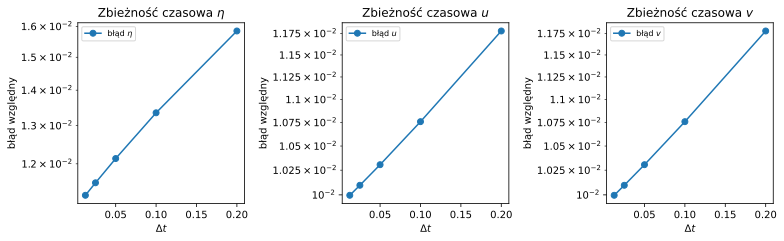

In [33]:
fig, ax = pyplot.subplots(1, 3, figsize=(11, 3.5))

for j, (key, label) in enumerate([
    ("eta", r"$\eta$"),
    ("u", r"$u$"),
    ("v", r"$v$")
]):
    ax[j].semilogy(dts, err_time[key], "o-", label=f"błąd {label}")
    ax[j].set(xlabel=r"$\Delta t$", ylabel="błąd względny", title=f"Zbieżność czasowa {label}")
    ax[j].legend(fontsize=8)

fig.tight_layout()
show_plot(fig=fig)

# Wnioski

Lokalne ujście masy powoduje powstanie ujemnej anomalii wysokości, a gradient
ciśnienia uruchamia przepływ w kierunku centrum zaburzenia. Siła Coriolisa
odchyla przepływ, dzięki czemu powstaje uporządkowana cyrkulacja cykloniczna.
Tarcie Rayleigha ogranicza amplitudę prędkości i stabilizuje rozwiązanie.
Rozwiązanie analityczne wykorzystane w analizie opisuje układ zlinearyzowany.
Dla małego wymuszenia $q_0$ rozwiązania numeryczne dla $\eta$, $u$ i $v$
pokrywają się z nim bardzo dobrze.
Błędy względne wszystkich trzech zmiennych maleją wraz ze zwiększaniem
rozdzielczości przestrzennej. Zmniejszanie kroku czasowego również redukuje
błąd, aż do osiągnięcia poziomu ograniczonego przez błąd przestrzenny
i przybliżenie liniowe.
Przeprowadzona analiza potwierdza poprawną implementację solvera oraz
zgodność otrzymanej dynamiki z oczekiwanym mechanizmem powstawania wiru.